# Рекуррентные нейронные сети (RNN)

### Особенности рекуррентных нейронных сетей

Большинство существующих методов машинного обучения работают с признаковым описанием фиксированной длины.

Так правильно делать в случае табличных данных — обычно каждый объект в таблицах описан фиксированным набором признаков, и новые признаки не могут появиться "вдруг". Мы точно знаем, что на вход нам приходит объект размера 100, а на выходе мы должны для него предсказать 1 число.

Верно это и про данные в виде изображений — обычно, нейронная сеть учится на изображениях определенного разрешения. Да, иногда вручную можно настроить так, чтобы нейронная сеть работала с изображением почти любого разрешения, но это происходит за счет вставки слоев global pooling, которые просто приводят любое признаковое описание, полученное нейронной сетью, а точнее, ее сверточной частью, ранее, к фиксированному размеру.

Однако многие данные структурой фиксированной длины не обладают. К примеру — тексты. Возьмем все абзацы из "Войны и Мира". Какие-то будут больше, какие-то меньше. И обрезать их как-то нельзя. Аналогично будет и для текстов из твиттера и тд. И что делать, если мы хотим предсказывать, например, эмоциональную окрашенность текста?

Более того, а что делать, если, к примеру, на основе абзаца текста нам необходимо сгенерировать его краткое содержание? То есть и то, что нужно предсказать, у нас может быть разной длины. Аналогично — мы хотим по данным о курсе валюты за прошлый год спрогнозировать курс валюты на следующий месяц по дням.

Таким образом, есть целый набор задач, для которых необходима особая структура нейронной сети, позволяющая так или иначе принимать данные разного размера.

### Примеры задач

**Анализ временных рядов**
- Табличные данные
- Аннотирование изображений и видео (Image/Video captioning)
- Машинный перевод
- Распознавание текста
- Распознавание речи


**Генеративные модели**
- Генерация текста/речи (например, чат - боты)
- Генерация изображений

**Классификация**
- Изображения
- Блоки текста (Sentiment analysis)

**Анализ последовательностей**
- анализ текстов
- биологические последовательности 
- химические последовательности


Общее для задач - имеется возможность сохранять информацию, сформированную при обработке одной части объекта (**токена**), и использовать ее, когда мы анализируем другие части.

До прихода нейронных сетей предложения пытались описать при помощи набора правил - грамматик, которые довольно успешно могли генерировать новые осмысленные предложения. Так выглядит разбор при помощи грамматик простого предложения

<img src ="https://edunet.kea.su/repo/EduNet-content/L08/out/parse_tree.png" width="500">

Однако грамматики плохо учитывали более глобальные связи. Например, очень тяжело было добиться того, чтобы в абзаце текста:

"Леша пришел домой. Он будет есть рыбу"

Компьютер понял, что во втором предложении "Он" соответствует "Леше". 

Основная идея, на которой основано RNN, состоит в следующем &mdash; возьмем всю последовательность и пропустим через одну и туже нейронную сеть. 
Но при этом сама нейронная сеть кроме следующего элемента последовательности (например, слова в тексте), будет принимать еще один параметр &mdash; некий $v$, который в начале будет, например, вектором из нулей, а далее &mdash; значением, которое выдает сама нейронная сеть после обработки очередного элемента последовательности (**токена**)

Также далее мы будем использовать понятие **нулевого токена** - токена, который символизирует заплатку, токен, не несущий никакого смысла, но который иногда нужно передать модели. Например - как сигнал начала работы

В этом $v$ (чаще обозначается $h$) &mdash; будет храниться hidden state, состояние, учитывающее и локальный, и глобальный контекст.

<img src ="https://edunet.kea.su/repo/EduNet-web_dependencies/L08/rnn_idea.png" width="800">

[Recurrent neural network](https://en.wikipedia.org/wiki/Recurrent_neural_network)

При этом нейронная сеть может выдавать некий ответ на каждом шаге, но мы можем:

 1. Использовать только выданное на последнем (если нам нужно предсказать одно значение) &mdash; many-to-one

 2. Можно подавать в нейронную сеть токены (когда кончился исходный сигнал &mdash; подаем нулевые токены), пока она не сгенерирует токен, символизирующий остановку (many-to-many, one-to-many)

 3. Можно делать различные комбинации, игнорируя выходы нейронной сети в начале, например

«One to one» &mdash; обычная нейронная сеть, RNN здесь не нужно

Более сложной является реализация «one to many», когда есть всего один вход и нам необходимо сформировать несколько выходов. Такой тип нейронной сети актуален, когда мы говорим о генерации музыки или текстов. Мы задаем начальное слово или начальный звук, а дальше модель начинает самостоятельно генерировать выходы, в качестве входа к очередной ячейке рассматривая выход с прошлой ячейки нейронной сети.

Если мы рассматриваем задачу классификации, то актуальна схема «many to one». Мы должны проанализировать все входы нейронной сети и только в конце определиться с классом.
 
Схему «many to many», когда количество выходов равно количеству входов нейронной сети. Обычно это задачи вида: разметить исходную последовательность. Например - указать столицы городов, названия важных объектов, веществ и т.д, что относится к задачам вида NER (Named entity recogition).
  
Ну и последней разновидностью нейронных сетей является сеть вида «many to many», когда количество выходов нейронной сети не равно количеству входов. Это актуально, к примеру, в машинном переводе, когда одна и та же фраза может иметь разное количество слов в разных языках (т.е. это реализует схему кодировщик-декодировщик). Кодировщик получает данные различной длины &mdash; например, предложение на английском языке. С помощью скрытых состояний он формирует из исходных данных вектор, который затем передается в декодировщик. Последний, в свою очередь, генерирует из полученного вектора выходные данные &mdash; исходную фразу, переведенную на другой язык.

<img src ="https://edunet.kea.su/repo/EduNet-content/L08/out/one_or_many_to_one_or_many_ways.png" width="1000">

Можно объединять разные подходы. Сначала генерируем некий $h$, который содержит сжатую информацию о том, что было подано в нейронную сеть, а затем подаем его в нейронную сеть «one to many», которая генерирует, к примеру, перевод того текста, что был подан первой части нейронной сети. 

<img src ="https://edunet.kea.su/repo/EduNet-content/L08/out/sequence_to_sequence.png" width="900">

### Базовый RNN блок

Рассмотрим работу рекуррентной нейронной сети:
1. На вход нейронной сети поступает некоторая последовательность $x = \{x_1,...x_t,...,x_n\}$. 

2. Для каждого поступившего $x_t$ формируется скрытое состояние $h_t$, которое является функцией от предыдущего состояния $h_{t-1}$ и текущего элемента последовательности $x_t$:
$$h_t = f_W(h_{t-1}, x_t),$$
где $W$  - это обучаемые параметры (веса).

3. На основании рассчитанного скрытого состояния, учитывающего предыдущие значения  $x_i$ формируется выходная последовательность $y = \{y_1,...y_t,...,y_k\}$. Для формирования предсказания $y_t$ в текущий момент времени в модель могут быть добавлены полносвязные слои, принимающие на вход текущее скрытое состояние $h_t$.

Ниже представлена простая RNN. В качестве функции активации используется тангенс. 

<img src ="https://edunet.kea.su/repo/EduNet-content/L08/out/rnn_basic_block.png" width="700">

Важное отличие от слоев, с которыми мы уже сталкивались, состоит в том, что на выходе мы получаем два объекта: $y_t$ и $h_t$.

$y_t$ &mdash; предсказание в текущий момент времени, например метка класса.

$h_t$ &mdash; контекст, в котором предсказание было сделано. Он может использоваться для дальнейших предсказаний.

### RNNCell

В Pytorch для вычисления $h_t$ используется модуль [RNNCell](https://pytorch.org/docs/stable/generated/torch.nn.RNNCell.html)  

$y_t$ в нем не вычисляется, предполагается, что для его получения в модель должен быть добавлен дополнительный линейный слой.

**`input_size`** &mdash;  размер элемента последовательности.

В отличие от сверточных, это всегда вектор, а не тензор, поэтому **`input_size`** &mdash;  скаляр.

**`hidden_size`** &mdash; тоже скаляр. Он задает размер скрытого состояния, которое тоже является вектором. Фактически это количество нейронов в слое.

In [1]:
import torch

rnn_cell = torch.nn.RNNCell(input_size=3, hidden_size=2)
dummy_sequence = torch.randn((1, 3)) # batch, input_size
h = rnn_cell(dummy_sequence) 
print("Inital shape:".ljust(17), f"{dummy_sequence.shape}")
print("Resulting shape:".ljust(17), f"{h.shape}")  # hidden state 

Inital shape:     torch.Size([1, 3])
Resulting shape:  torch.Size([1, 2])


Внутри происходит примерно следующее:  
Для понятности в данном примере опущена батчевая обработка.

In [2]:
import numpy as np
from torch import nn

# Simple RNNcell without a bias and batch support
class SimplifiedRNNCell(nn.Module): 
  def __init__(self, input_size, hidden_size):
    super().__init__()
    # Init weight matrix, for simplicity omit bias
    self.W_hx = np.random.randn(input_size, hidden_size) * 0.0001 # hidden_size == number of neurons
    self.W_hh = np.random.randn(hidden_size, hidden_size) * 0.0001 # naive initialization
    self.h0 = np.zeros((hidden_size)) # Initial hidden state
  
  def forward(self, x, h=None): # Without a batch dimension
    if h is None:
      h = self.h0
    h = np.tanh(self.W_hx.T.dot(x) + self.W_hh.T.dot(h))
    return h 
  
simple_rnn_cell = SimplifiedRNNCell(input_size=3, hidden_size=2)
h = simple_rnn_cell(dummy_sequence[0]) # No batch 
print(f"Out = h\n{h.shape} \n{h}")

Out = h
(2,) 
[5.17025185e-05 1.26412754e-04]


Однако в последовательности всегда несколько элементов. И надо применить алгоритм к каждому.

Поэтому RNNCell напрямую не используется. Для него есть обертка: [RNN](https://pytorch.org/docs/stable/generated/torch.nn.RNN.html) который обеспечивает последовательный вызов RNNCell для всех элементов последовательности.

### RNN блок в Pytorch 

In [3]:
rnn = torch.nn.RNN(input_size=3, hidden_size=2) # batch_first = True
dummy_batched_seq = torch.randn((2, 1, 3)) # seq_len, batch, input_size
out, h = rnn(dummy_batched_seq) 

print("Inital shape:".ljust(20), f"{dummy_batched_seq.shape}")
print("Resulting shape:".ljust(20), f"{out.shape}")
print("Hidden state shape:".ljust(20), f"{h.shape}")

Inital shape:        torch.Size([2, 1, 3])
Resulting shape:     torch.Size([2, 1, 2])
Hidden state shape:  torch.Size([1, 1, 2])


Внутри происходит примерно следующее:

In [4]:
# Simple RNN without batching

class SimplifiedRNNLayer(nn.Module): 
  def __init__(self, input_size, hidden_size):
    super().__init__()
    self.rnn_cell = SimplifiedRNNCell(input_size, hidden_size)

  # Without a batch dimension x have shape seq_len * input_size
  def forward(self, x, h=None):
    all_h = []
    for i in range(x.shape[0]): # iterating over timestamps
      h = self.rnn_cell(x[i], h)
      all_h.append(h) 
    return  np.stack(all_h), h

simple_rnn = SimplifiedRNNLayer(input_size=4, hidden_size=2)
sequence = np.array([[0, 1, 2, 0], [3, 4, 5, 0]]) # batch with one sequence of two elements 

out, h = simple_rnn(sequence)
print("Inital shape:".ljust(20), f"{sequence.shape}")
print("Resulting shape:".ljust(20), f"{out.shape}")
print("Hidden state shape:".ljust(20), f"{h.shape}")

Inital shape:        (2, 4)
Resulting shape:     (2, 2)
Hidden state shape:  (2,)


К данным добавляется еще одно измерение размер последовательности. Таким образом, batch из 5 последовательностей по 6 элементов в каждой будет выглядеть так (время идёт первой размерностью, потому поэлементно идём "сверху вниз"):

<img src ="https://edunet.kea.su/repo/EduNet-content/L08/out/rnn_batch.png" width="600">

Размер самого элемента == 3

Внутри RNN модуля элементы последовательности обрабатываются последовательно:

<img src = "https://edunet.kea.su/repo/EduNet-content/L08/out/simple_rnn_h_state.png" width="700">

Веса при этом используются одни и те же.

In [5]:
dummy_seq = torch.randn((2, 1, 3)) #  seq_len, batch, input_size

print("RNNCell")
rnn_cell = torch.nn.RNNCell(3, 2)
print("Parameter".ljust(10), "Shape")
for t, p in rnn_cell.named_parameters():
  print(t.ljust(10), p.shape) 

cell_out = rnn_cell(dummy_seq[0, :, :]) # take first element from sequence 
print()
print("Result shape =".ljust(20), cell_out.shape)
print("Hidden state shape =".ljust(20), cell_out.shape) # one hidden state

print('----------------------------------------')

print("RNN")
rnn = torch.nn.RNN(3, 2)
print("Parameter".ljust(15), "Shape")
for t, p in rnn.named_parameters():
  print(t.ljust(15), p.shape) 

out, h = rnn(dummy_seq)

print()
print("Result shape =".ljust(20), out.shape) # h for all timestamps element
print("Hidden state shape =".ljust(20), cell_out.shape) # h for last element

RNNCell
Parameter  Shape
weight_ih  torch.Size([2, 3])
weight_hh  torch.Size([2, 2])
bias_ih    torch.Size([2])
bias_hh    torch.Size([2])

Result shape =       torch.Size([1, 2])
Hidden state shape = torch.Size([1, 2])
----------------------------------------
RNN
Parameter       Shape
weight_ih_l0    torch.Size([2, 3])
weight_hh_l0    torch.Size([2, 2])
bias_ih_l0      torch.Size([2])
bias_hh_l0      torch.Size([2])

Result shape =       torch.Size([2, 1, 2])
Hidden state shape = torch.Size([1, 2])


### Слои (Stacked RNNs)

RNN блоки можно объединять в слои, накладывая их друг на друга. Для этой операции в `torch.nn.RNN` есть аргумент `num_layers`, с помощью которого можно указать количество слоев.

<img src ="http://edunet.kea.su/repo/EduNet-content/L08/out/layers.png" width="600">

In [6]:
dummy_input = torch.randn((2, 1, 3))  #seq_len, batch, input_size
rnn = torch.nn.RNN(3, 2, num_layers=3)

# Weights matrix sizes not changed!
for t, p in rnn.named_parameters():
    print(t, p.shape) 

out, h = rnn(dummy_input)

print("Out:\n", out.shape) # Hidden states for all elements from top layer
print("h:\n", h.shape) # Hidden states for last element for all layers

weight_ih_l0 torch.Size([2, 3])
weight_hh_l0 torch.Size([2, 2])
bias_ih_l0 torch.Size([2])
bias_hh_l0 torch.Size([2])
weight_ih_l1 torch.Size([2, 2])
weight_hh_l1 torch.Size([2, 2])
bias_ih_l1 torch.Size([2])
bias_hh_l1 torch.Size([2])
weight_ih_l2 torch.Size([2, 2])
weight_hh_l2 torch.Size([2, 2])
bias_ih_l2 torch.Size([2])
bias_hh_l2 torch.Size([2])
Out:
 torch.Size([2, 1, 2])
h:
 torch.Size([3, 1, 2])


### Bidirectional (двунаправленность)

Последовательность можно пропустить через сеть два раза: в прямом и обратном направлении. Для этого создаётся слой, аналогичный входному, для обратного направления, и результат двух слоёв конкатинируется.

[Understanding RNN implementation in PyTorch](https://medium.com/analytics-vidhya/understanding-rnn-implementation-in-pytorch-eefdfdb4afdb)

<img src ="http://edunet.kea.su/repo/EduNet-content/L08/out/bidirectional.png" width="700">

In [7]:
dummy_input = torch.randn((2, 1, 3))  #seq_len, batch, input_size
rnn = torch.nn.RNN(3, 2, bidirectional=True)

for t, p in rnn.named_parameters():
    print(t, p.shape) 

out, h = rnn(dummy_input)

print("Out:\n", out.shape) # Concatenated Hidden states from both layers
print("h:\n", h.shape) # Hidden states last element from  both : 2*num_layers*hidden_state

weight_ih_l0 torch.Size([2, 3])
weight_hh_l0 torch.Size([2, 2])
bias_ih_l0 torch.Size([2])
bias_hh_l0 torch.Size([2])
weight_ih_l0_reverse torch.Size([2, 3])
weight_hh_l0_reverse torch.Size([2, 2])
bias_ih_l0_reverse torch.Size([2])
bias_hh_l0_reverse torch.Size([2])
Out:
 torch.Size([2, 1, 4])
h:
 torch.Size([2, 1, 2])


### Пример прогнозирования временного ряда

- [How to Remove Non-Stationarity in Time Series Forecasting](https://towardsdatascience.com/how-to-remove-non-stationarity-in-time-series-forecasting-563c05c4bfc7)
- [A Guide to Time Series Forecasting in Python](https://builtin.com/data-science/time-series-forecasting-python)
- [Detecting stationarity in time series data](https://towardsdatascience.com/detecting-stationarity-in-time-series-data-d29e0a21e638)
- [Most useful Python functions for Time Series Analysis](https://towardsdatascience.com/most-useful-python-functions-for-time-series-analysis-ed1a9cb3aa8b)
- [Data transformations and forecasting models: what to use and when](https://people.duke.edu/~rnau/whatuse.htm)

Что общего у прогнозирования потребления электроэнергии домохозяйствами, оценки трафика на дорогах в определенные периоды, прогнозировании паводков и прогнозировании цены, по которой акции будут торговаться на фондовой бирже?

Все они подпадают под понятие данных временных рядов. Вы не можете точно предсказать любой из этих результатов без компонента «время». И по мере того, как в мире вокруг нас генерируется все больше и больше данных, прогнозирование временных рядов становится все более важной областью применения методов ML и DL.

### Подготовка данных 

[Time Series Prediction with LSTM Using PyTorch](https://colab.research.google.com/github/dlmacedo/starter-academic/blob/master/content/courses/deeplearning/notebooks/pytorch/Time_Series_Prediction_with_LSTM_Using_PyTorch.ipynb#scrollTo=NabsV8O5BBd5https://colab.research.google.com/github/dlmacedo/starter-academic/blob/master/content/courses/deeplearning/notebooks/pytorch/Time_Series_Prediction_with_LSTM_Using_PyTorch.ipynb#scrollTo=NabsV8O5BBd5)

### Загрузка данных

Air Passengers per month.  
[Dataset Air Passengers Number of air passengers per month](https://www.kaggle.com/rakannimer/air-passengers)

In [8]:
import pandas as pd
dataset = pd.read_csv('https://edunet.kea.su/repo/EduNet-web_dependencies/L08/airline-passengers.csv')
dataset.head()

,Month,Passengers
0,1949-01,112
1,1949-02,118
2,1949-03,132
3,1949-04,129
4,1949-05,121


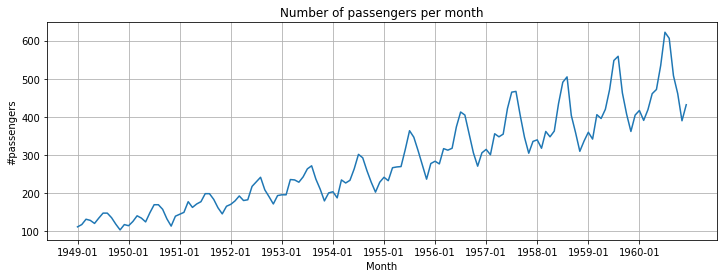

In [9]:
import matplotlib.pyplot as plt

training_data = dataset.iloc[:, 1:2].values # transform dataframe to numpy.array
# plotting
plt.figure(figsize=(12, 4))
plt.plot(training_data, label='Airline Passangers Data')
plt.title("Number of passengers per month")
plt.ylabel("#passengers")
plt.xlabel("Month")
labels_to_display = [i for i in range(training_data.shape[0]) if i % 12 == 0]
plt.xticks(labels_to_display, dataset['Month'][labels_to_display])
plt.grid()
plt.show()

### Шкалирование данных

In [10]:
# Min - Max normalization
td_min = training_data.min()
td_max = training_data.max()
print('Initial statistics:')
print('Minimum value:', repr(td_min).rjust(5))
print('Maximum value:', repr(td_max).rjust(5))

training_data = (training_data - td_min) / (td_max - td_min)
print('\nResulting statistics:')
print('Minimum value:', repr(training_data.min()).rjust(5))
print('Maximum value:', repr(training_data.max()).rjust(5))

Initial statistics:
Minimum value:   104
Maximum value:   622

Resulting statistics:
Minimum value:   0.0
Maximum value:   1.0


### Формирование ансамблей данных

Поскольку мы хотим научиться предсказывать следующие значение на основе предыдущих, нам нужно подготовить данные соответствующим образом.

Разобьем весь массив данных на фрагменты вида

$x \to y$

где $x$ - это подпоследовательность, например записи с 1-й по 8-ю, а $y$ - это значение из 9-й записи, то самое, которое мы хотим предсказать.

In [11]:
import numpy as np
import torch

# create data "ensemble"
def sliding_windows(data, seq_length):
    x = []
    y = []

    for i in range(len(data) - seq_length):
        _x = data[i:(i + seq_length)] # picking several sequential observations
        _y = data[i+seq_length] # picking the subsequent observation
        x.append(_x)
        y.append(_y)

    return torch.Tensor(np.array(x)), torch.Tensor(np.array(y))
    
# set length of the ensemble; accuracy of the predictions and 
# speed perfomance almost always depend on it size
seq_length = 8 # compare 2 and 32
x, y = sliding_windows(training_data, seq_length)
print("Example of the obtained data:\n")
print("Data corresponding to the first x:")
print(x[0])
print("Data corresponding to the first y:")
print(y[0])

Example of the obtained data:

Data corresponding to the first x:
tensor([[0.0154],
        [0.0270],
        [0.0541],
        [0.0483],
        [0.0328],
        [0.0598],
        [0.0849],
        [0.0849]])
Data corresponding to the first y:
tensor([0.0618])


Благодаря такому подходу, мы можем работать с RNN моделью так же, как работали со сверточными моделями. Подавая на вход такую подпоследовательность + результат.

### Разобьем на train и test

In [12]:
train_size = int(len(y) * 0.8)

x_train = x[:train_size]
y_train = y[:train_size]

x_test = x[train_size:]
y_test = y[train_size:]

print("Train data:")
print("x shape:", x_train.shape)
print("y shape:", y_train.shape)

print("\nTest data:")
print("x shape:", x_test.shape)
print("y shape:", y_test.shape)

Train data:
x shape: torch.Size([108, 8, 1])
y shape: torch.Size([108, 1])

Test data:
x shape: torch.Size([28, 8, 1])
y shape: torch.Size([28, 1])


### Создание и обучение модели

In [13]:
import torch.nn as nn

class AirTrafficPredictor(nn.Module):

    def __init__(self, input_size, hidden_size):
        # hidden_size == number of neurons 
        super().__init__()
        self.rnn = nn.RNN(input_size=input_size, hidden_size=hidden_size, batch_first=True)
        self.fc = nn.Linear(hidden_size, 1) # Predict only one value

    def forward(self, x):
        #print("x: ",x.shape) # 108 x 8 x 1 : [batch_size, seq_len, input_size] 
        out, h = self.rnn(x) 
        #print("out: ", out.shape) # 108 x 8 x 4 : [batch_size, seq_len, hidden_size] Useless!
        #print("h : ", h.shape) # 1 x 108 x 4 [ num_layers, batch_size, hidden_size]
        y = self.fc(h)
        #print("y",y.shape) # 1 x 108 x 1
        return y, h

### Обучение

В силу того, что набор данных маленький, все данные поместились в один batch, итерирования по batch-ам в явном виде здесь не происходит.

In [14]:
def time_series_train(model, num_epochs=2000, learning_rate=0.01):
  
  criterion = torch.nn.MSELoss() # mean-squared error for regression
  optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

  # Train the model
  for epoch in range(num_epochs):
      y_pred, h = model(x_train) # we don't use h there, but we can!
      optimizer.zero_grad()
      
      # obtain the loss
      loss = criterion(y_pred[0], y_train) # for shape compatibility
      loss.backward()
      
      optimizer.step()
      if epoch % 100 == 0:
          print(f"Epoch: {epoch},".ljust(15), "loss: %1.5f" % (loss.item()))

print("Simple RNN training process with MSE loss:")
input_size = 1
hidden_size = 4 
rnn = AirTrafficPredictor(input_size, hidden_size)
time_series_train(rnn)

Simple RNN training process with MSE loss:
Epoch: 0,       loss: 0.18441
Epoch: 100,     loss: 0.00427
Epoch: 200,     loss: 0.00314
Epoch: 300,     loss: 0.00280
Epoch: 400,     loss: 0.00255
Epoch: 500,     loss: 0.00245
Epoch: 600,     loss: 0.00243
Epoch: 700,     loss: 0.00242
Epoch: 800,     loss: 0.00240
Epoch: 900,     loss: 0.00239
Epoch: 1000,    loss: 0.00237
Epoch: 1100,    loss: 0.00235
Epoch: 1200,    loss: 0.00233
Epoch: 1300,    loss: 0.00234
Epoch: 1400,    loss: 0.00234
Epoch: 1500,    loss: 0.00221
Epoch: 1600,    loss: 0.00219
Epoch: 1700,    loss: 0.00213
Epoch: 1800,    loss: 0.00214
Epoch: 1900,    loss: 0.00210


### Тестирование

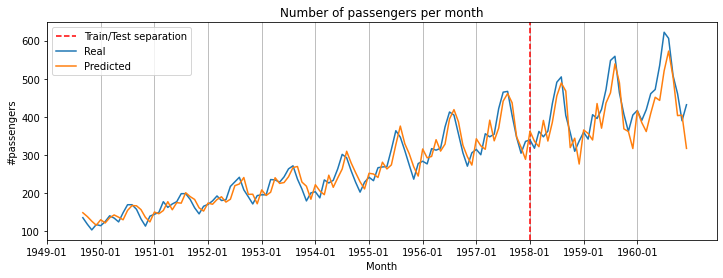

In [15]:
def time_series_plot(train_predict):
  data_predict = train_predict.data
  y_data_plot = y.data

  # Denormalize
  data_predict = data_predict[0] * (td_max - td_min) + td_min
  y_data_plot = y_data_plot * (td_max - td_min) + td_min 

  # Ploitting
  plt.figure(figsize=(12, 4))
  plt.axvline(x=train_size, c='r', linestyle='--')
  # shifting the curve as first y-value not correspond first value overall
  plt.plot(seq_length + np.arange(y_data_plot.shape[0]), y_data_plot)
  plt.plot(seq_length + np.arange(y_data_plot.shape[0]), data_predict)
  
  plt.title("Number of passengers per month")
  plt.ylabel("#passengers")
  plt.xlabel("Month")
  plt.xticks(labels_to_display, dataset['Month'][labels_to_display])
  
  plt.legend(['Train/Test separation', 'Real', 'Predicted'])
  plt.grid(axis='x')
  plt.show()

rnn.eval()
train_predict, h = rnn(x)
time_series_plot(train_predict)

Модель в принципе справляется с задачей.

### Пример посимвольной генерации текста

[Github RNN-walkthrough](https://github.com/gabrielloye/RNN-walkthrough/blob/master/main.ipynb)

Одним из основных направлений использования рекуррентных сетей является работа с текстами:
- генерация (Language modeling)  
и 
- перевод (Machine Translation)

Давайте посмотрим, как решаются такого рода задачи.

Начнем с относительно простой - посимвольной генерации текста.

**Постановка задачи:**

предсказать следующий символ в последовательности.

- исходный текст:  
'hey how are you'

- искаженный текст:  
'hey how are yo'

- Верное предсказание:
'u'


Теоретически эту технику можно использовать для генерации подсказок при наборе текстов, исправления ошибок или восстановления частично утраченного текста.

<img src ="https://edunet.kea.su/repo/EduNet-web_dependencies/L08/character_by_character_generation_example.gif" width="400">

[The Unreasonable Effectiveness of Recurrent Neural Networks](http://karpathy.github.io/2015/05/21/rnn-effectiveness/)

### Подготовка данных

1. Зафиксировать словарь
2. Разбить данные
3. Выполнить кодирование символов 

In [16]:
import pprint

text = ['hey how are you','good i am fine','have a nice day']

# Join all the sentences together and extract the unique characters 
# from the combined sentences
chars = set(''.join(text))

# Creating a dictionary that maps integers to the characters
int2char = dict(enumerate(chars))

# Creating another dictionary that maps characters to integers
char2int = {char: ind for ind, char in int2char.items()}

print("Dictionary for mapping character to the integer:")
pprint.pprint(char2int)

Dictionary for mapping character to the integer:
{' ': 9,
 'a': 1,
 'c': 15,
 'd': 16,
 'e': 2,
 'f': 13,
 'g': 3,
 'h': 8,
 'i': 6,
 'm': 12,
 'n': 7,
 'o': 11,
 'r': 4,
 'u': 5,
 'v': 14,
 'w': 0,
 'y': 10}


Вместо ASCII символа, каждой букве мы сопоставили номер.

### Выравнивание данных (Padding)

RNN допускают работу с данными переменной длины. Но чтобы поместить предложения в batch надо их выровнять.


Обычно размер батча делают равным самому длинному предложению, а остальные просто дополняют пробелами до этого размера.

In [17]:
lengths = [len(sent) for sent in text]
maxlen = max(lengths)
print(f"The longest string has {maxlen} characters.\n")

print(f"Initial texts:\n{text}")
# A simple loop that loops through the list of sentences and adds
# a ' ' whitespace until the length of the sentence matches
# the length of the longest sentence
for i in range(len(text)):
    while len(text[i])<maxlen:
        text[i] += ' '

print(f'Resulting texts:\n{text}')

The longest string has 15 characters.

Initial texts:
['hey how are you', 'good i am fine', 'have a nice day']
Resulting texts:
['hey how are you', 'good i am fine ', 'have a nice day']


### Разбиение данных

В качестве входа будем использовать предложение без последнего символа:

**'hey how are yo'**

, а в качестве результата - предложение, в котором он сгенерирован.

**'ey how are you'**

In [18]:
# Creating lists that will hold our input and target sequences
input_seq = []
target_seq = []

for i in range(len(text)):
    # Remove last character for input sequence
    input_seq.append(text[i][:-1])
    
    # Remove firsts character for target sequence
    target_seq.append(text[i][1:])
    
    print("Input sequence:".ljust(18), f"'{input_seq[i]}'")
    print("Target sequence:".ljust(18), f"'{target_seq[i]}'")
    print()

Input sequence:    'hey how are yo'
Target sequence:   'ey how are you'

Input sequence:    'good i am fine'
Target sequence:   'ood i am fine '

Input sequence:    'have a nice da'
Target sequence:   'ave a nice day'



### Кодирование

Теперь символы надо перевести в числа. Для этого мы уже построили словарь.

P.S. Запускать блок только один раз.

In [19]:
for i in range(len(text)):
    input_seq[i] = [char2int[character] for character in input_seq[i]]
    target_seq[i] = [char2int[character] for character in target_seq[i]]

    print("Encodded input sequence:".ljust(25), input_seq[i])
    print("Encodded target sequence:".ljust(25), target_seq[i])
    print()

Encodded input sequence:  [8, 2, 10, 9, 8, 11, 0, 9, 1, 4, 2, 9, 10, 11]
Encodded target sequence: [2, 10, 9, 8, 11, 0, 9, 1, 4, 2, 9, 10, 11, 5]

Encodded input sequence:  [3, 11, 11, 16, 9, 6, 9, 1, 12, 9, 13, 6, 7, 2]
Encodded target sequence: [11, 11, 16, 9, 6, 9, 1, 12, 9, 13, 6, 7, 2, 9]

Encodded input sequence:  [8, 1, 14, 2, 9, 1, 9, 7, 6, 15, 2, 9, 16, 1]
Encodded target sequence: [1, 14, 2, 9, 1, 9, 7, 6, 15, 2, 9, 16, 1, 10]



#### One-hot encoding

Теперь из чисел надо сделать вектора. 


Почему бы не оставить числа?
В прошлом примере модель хорошо с ними работала.

В прошлом примере использовался MSE, и на выходе было число.

Если бы мы определили отношение порядка над номерами букв, то что-то подобное можно было бы сделать.

Однако сейчас мы предсказываем класс буквы.
Поэтому на входе и на выходе должен быть вектор.

<img src ="https://edunet.kea.su/repo/EduNet-content/L08/out/one_hot_encoding_softmax.png" width="250">

In [20]:
import numpy as np

dict_size = len(char2int)
seq_len = maxlen - 1
batch_size = len(text)

def one_hot_encode(sequence, dict_size, seq_len, batch_size):
    # Creating a multi-dimensional array of zeros with the desired output shape
    features = np.zeros((batch_size, seq_len, dict_size), dtype=np.float32)
    
    # Replacing the 0 at the relevant character index with a 1 to represent that character
    for i in range(batch_size):
        for u in range(seq_len):
            features[i, u, sequence[i][u]] = 1
    return features

input_seq = one_hot_encode(input_seq, dict_size, seq_len, batch_size)
print("Input shape: {} --> (Batch Size, Sequence Length, One-Hot Encoding Size)".format(input_seq.shape))
print(input_seq[0])

Input shape: (3, 14, 17) --> (Batch Size, Sequence Length, One-Hot Encoding Size)
[[0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]]


Каждый символ закодировали вектором.
Не слишком экономно, зато удобно умножать на матрицу весов.

P.S. Запускать только один раз

<img src ="https://edunet.kea.su/repo/EduNet-content/L08/out/language_modeling.png" width="700">

In [21]:
# Convert data to tensor
import torch

input_seq = torch.Tensor(input_seq)
target_seq = torch.Tensor(target_seq)

## Создание и обучение модели

In [22]:
import torch.nn as nn
class NextCharacterGenerator(nn.Module):
    def __init__(self, input_size, output_size, hidden_dim, n_layers):
        super().__init__()

        # RNN Layer
        self.rnn = nn.RNN(input_size, hidden_size=hidden_dim, batch_first=True)   
        # Fully connected layer
        self.fc = nn.Linear(hidden_dim, output_size)
    
    def forward(self, x):
        batch_size = x.size(0)
        #Initializing hidden state for first input using method defined below
        hidden_0 = torch.zeros(1, batch_size, self.rnn.hidden_size) # 1 correspond to number of layers

        # Passing in the input and hidden state into the model and obtaining outputs
        out, hidden = self.rnn(x, hidden_0)
        
        # Reshaping the outputs such that it can be fit into the fully connected layer
        # Need Only if n_layers > 1
        out = out.contiguous().view(-1, self.rnn.hidden_size)
        out = self.fc(out)
        
        return out, hidden

### Обучение

In [23]:
# Instantiate the model with hyperparameters
model = NextCharacterGenerator(input_size=dict_size, output_size=dict_size, hidden_dim=12, n_layers=1)

# Define hyperparameters
num_epochs = 100

# Define Loss, Optimizer
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

# Training Run
for epoch in range(1, num_epochs + 1):
    optimizer.zero_grad() # Clears existing gradients from previous epoch
    output, hidden = model(input_seq)
    loss = criterion(output, target_seq.view(-1).long())
    loss.backward() # Does backpropagation and calculates gradients
    optimizer.step() # Updates the weights accordingly
    
    if epoch % 10 == 0:
        print(f'Epoch: {epoch}/{num_epochs}'.ljust(20), end=' ')
        print("Loss: {:.4f}".format(loss.item()))

Epoch: 10/100        Loss: 2.4908
Epoch: 20/100        Loss: 2.0503
Epoch: 30/100        Loss: 1.5923
Epoch: 40/100        Loss: 1.1411
Epoch: 50/100        Loss: 0.7643
Epoch: 60/100        Loss: 0.5065
Epoch: 70/100        Loss: 0.3390
Epoch: 80/100        Loss: 0.2372
Epoch: 90/100        Loss: 0.1756
Epoch: 100/100       Loss: 0.1380


### Тест

In [24]:
def predict(model, character):
    # One-hot encoding our input to fit into the model
    character = np.array([[char2int[c] for c in character]])
    character = one_hot_encode(character, dict_size, character.shape[1], 1)
    character = torch.from_numpy(character)
    
    out, hidden = model(character)
    #print(out.shape)
    #print(out)
    prob = nn.functional.softmax(out[-1], dim=0).data
    # Taking the class with the highest probability score from the output
    char_ind = torch.max(prob, dim=0)[1].item()

    return int2char[char_ind], hidden

def sample(model, out_len, start='hey'):
    model.eval() # eval mode
    start = start.lower()
    # First off, run through the starting characters
    chars = [ch for ch in start]
    size = out_len - len(chars)
    # Now pass in the previous characters and get a new one
    for _ in range(size):
        char, h = predict(model, chars)
        chars.append(char)

    return ''.join(chars)

sample(model, 15, 'good')

'good i am fine '

### Проблемы RNN

Теоретически, можно было бы сразу пропустить все данные через сеть и затем вычислить градиент, однако возникнут следующие проблемы:

 - Большие последовательности не поместятся в памяти
 - Поскольку цепочка будет очень длинной, то возникнет исчезновение/взрыв градиента
 - По мере прохождения сигнала по цепи контекст затирается

Исчезающий/взрывающийся градиент (Vanishing/exploding gradient) - явления исчезающего и взрывающегося градиента часто встречаются в контексте RNN. И при большой длине последовательности это становится критичным. Причина в том, что зависимость величины градиента от числа слоёв экспоненциальная, поскольку веса умножаются многократно.

$dL ∝ (W)^N$.

$W > 1$ => взрыв

$W < 1$ => затухание

<img src ="http://edunet.kea.su/repo/EduNet-content/L08/out/498_FA2019_lecture12-086.png" >

Один из путей решения проблемы: градиентное отсечение (Gradient clipping) - метод, который ограничивает максимально допустимое значение градиента, позволяя избежать градиентного взрыва.